# Deep Learning Assignment 2 – Daily Weather Forecasting Using RNN



## 1. Import Required Libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the Dataset

In [3]:
# If the CSV is not in the notebook folder, update this path.
df = pd.read_csv("weatherHistory.csv")

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
5,2006-04-01 05:00:00.000 +0200,Partly Cloudy,rain,9.222222,7.111111,0.85,13.9587,258.0,14.9569,0.0,1016.66,Partly cloudy throughout the day.
6,2006-04-01 06:00:00.000 +0200,Partly Cloudy,rain,7.733333,5.522222,0.95,12.3648,259.0,9.9820,0.0,1016.72,Partly cloudy throughout the day.
7,2006-04-01 07:00:00.000 +0200,Partly Cloudy,rain,8.772222,6.527778,0.89,14.1519,260.0,9.9820,0.0,1016.84,Partly cloudy throughout the day.
8,2006-04-01 08:00:00.000 +0200,Partly Cloudy,rain,10.822222,10.822222,0.82,11.3183,259.0,9.9820,0.0,1017.37,Partly cloudy throughout the day.
9,2006-04-01 09:00:00.000 +0200,Partly Cloudy,rain,13.772222,13.772222,0.72,12.5258,279.0,9.9820,0.0,1017.22,Partly cloudy throughout the day.


## 3. Understand the Dataset

In [5]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  str    
 1   Summary                   96453 non-null  str    
 2   Precip Type               95936 non-null  str    
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  str    
dtypes: float64(8), str(4)
memory usage: 8.8 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Formatted Date,96453,96429,2010-08-02 00:00:00.000 +0200,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Summary,96453,27,Partly Cloudy,31733,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Precip Type,95936,2,rain,85224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temperature (C),96453.0,NaN,NaN,NaN,11.932678,9.551546,-21.822222,4.688889,12.0,18.838889,39.905556
Apparent Temperature (C),96453.0,NaN,NaN,NaN,10.855029,10.696847,-27.716667,2.311111,12.0,18.838889,39.344444
Humidity,96453.0,NaN,NaN,NaN,0.734899,0.195473,0.0,0.6,0.78,0.89,1.0
Wind Speed (km/h),96453.0,NaN,NaN,NaN,10.81064,6.913571,0.0,5.8282,9.9659,14.1358,63.8526
Wind Bearing (degrees),96453.0,NaN,NaN,NaN,187.509232,107.383428,0.0,116.0,180.0,290.0,359.0
Visibility (km),96453.0,NaN,NaN,NaN,10.347325,4.192123,0.0,8.3398,10.0464,14.812,16.1
Loud Cover,96453.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Check Missing Values and Duplicates

In [6]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64

Duplicate rows: 24


## 5. Data Cleaning and Date Processing
Convert the timestamp to a standard datetime value, remove duplicate records, and prepare the numeric weather columns.

In [7]:
df = df.drop_duplicates().copy()

# Convert timestamps to UTC so that observations can be grouped consistently by day.
df["Formatted Date"] = pd.to_datetime(df["Formatted Date"], errors="coerce", utc=True)
df = df.dropna(subset=["Formatted Date"])

numeric_columns = [
    "Temperature (C)",
    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Wind Bearing (degrees)",
    "Visibility (km)",
    "Pressure (millibars)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].median())

print("Shape after cleaning:", df.shape)
display(df[["Formatted Date"] + numeric_columns].head())

Shape after cleaning: (96429, 12)


,Formatted Date,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
0,2006-03-31 22:00:00+00:00,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13
1,2006-03-31 23:00:00+00:00,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63
2,2006-04-01 00:00:00+00:00,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94
3,2006-04-01 01:00:00+00:00,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41
4,2006-04-01 02:00:00+00:00,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51


## 6. Convert Hourly Data into Daily Weather Data
The original file contains hourly observations. We calculate the daily mean for each numerical weather feature.

In [8]:
df = df.set_index("Formatted Date").sort_index()

daily_df = df[numeric_columns].resample("D").mean()
daily_df = daily_df.dropna()

print("Daily dataset shape:", daily_df.shape)
display(daily_df.head())

Daily dataset shape: (4019, 7)


,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
Formatted Date,,,,,,,
2005-12-31 00:00:00+00:00,0.577778,-4.050000,0.890000,17.114300,140.000000,9.982000,1016.660000
2006-01-01 00:00:00+00:00,4.075000,-0.174537,0.817083,21.229192,142.750000,11.348487,1011.985000
2006-01-02 00:00:00+00:00,5.263194,1.808796,0.847083,17.824713,164.583333,8.492079,1010.384167
2006-01-03 00:00:00+00:00,2.340509,0.445370,0.897083,7.726658,252.541667,9.223958,1021.170833
2006-01-04 00:00:00+00:00,2.251852,-0.663194,0.906667,12.152817,35.000000,8.352546,981.770833


## 7. Exploratory Data Analysis (EDA)

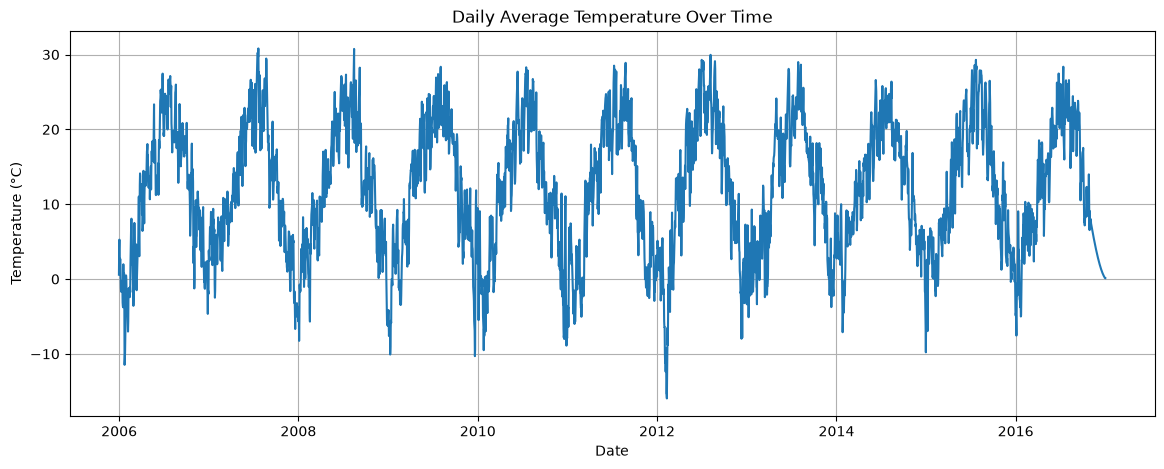

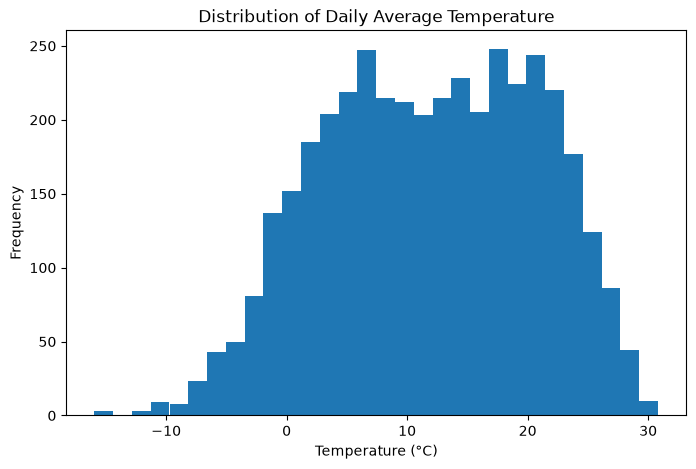

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
Temperature (C),1.000000,0.995746,-0.590933,-0.139562,0.049735,0.575732,-0.000511
Apparent Temperature (C),0.995746,1.000000,-0.573991,-0.190764,0.048464,0.554868,0.006905
Humidity,-0.590933,-0.573991,1.000000,-0.061724,-0.011020,-0.694201,-0.007766
Wind Speed (km/h),-0.139562,-0.190764,-0.061724,1.000000,0.157965,0.199219,-0.086517
Wind Bearing (degrees),0.049735,0.048464,-0.011020,0.157965,1.000000,0.099978,-0.043817
Visibility (km),0.575732,0.554868,-0.694201,0.199219,0.099978,1.000000,0.055727
Pressure (millibars),-0.000511,0.006905,-0.007766,-0.086517,-0.043817,0.055727,1.000000


In [9]:
plt.figure(figsize=(14, 5))
plt.plot(daily_df.index, daily_df["Temperature (C)"])
plt.title("Daily Average Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(daily_df["Temperature (C)"], bins=30)
plt.title("Distribution of Daily Average Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.show()

display(daily_df.corr())

## 8. Select Features and Target
Use daily weather measurements as input features. The target is the next day's average temperature.

In [10]:
feature_columns = numeric_columns
target_column = "Temperature (C)"

data = daily_df[feature_columns].copy()
print("Input features:", feature_columns)
print("Target:", target_column)

Input features: ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)']
Target: Temperature (C)


## 9. Split the Data Chronologically
Weather is time-series data, so we do not shuffle the observations. The first 80% is used for training and the remaining 20% for testing.

In [11]:
split_index = int(len(data) * 0.80)

train_data = data.iloc[:split_index]
print("Total daily records:", len(data))
print("Training records:", len(train_data))
print("Testing records:", len(data) - split_index)

Total daily records: 4019
Training records: 3215
Testing records: 804


## 10. Feature Scaling
Fit the scaler only on training data to avoid data leakage.

In [12]:
scaler = MinMaxScaler()
scaler.fit(train_data)

scaled_values = scaler.transform(data)
scaled_df = pd.DataFrame(scaled_values, index=data.index, columns=feature_columns)

display(scaled_df.head())

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
Formatted Date,,,,,,,
2005-12-31 00:00:00+00:00,0.353548,0.302407,0.849462,0.418660,0.401397,0.624523,0.961991
2006-01-01 00:00:00+00:00,0.428318,0.381726,0.744922,0.533583,0.409778,0.710859,0.955378
2006-01-02 00:00:00+00:00,0.453722,0.422318,0.787933,0.438501,0.476317,0.530389,0.953114
2006-01-03 00:00:00+00:00,0.391235,0.394413,0.859618,0.156478,0.744381,0.576630,0.968371
2006-01-04 00:00:00+00:00,0.389340,0.371724,0.873357,0.280094,0.081397,0.521573,0.912642


## 11. Create Time Sequences
The RNN receives the previous 7 days of weather data and learns to predict the temperature for the following day.

In [13]:
TIME_STEPS = 7

X, y, target_positions = [], [], []

temperature_index = feature_columns.index(target_column)

for i in range(TIME_STEPS, len(scaled_values)):
    X.append(scaled_values[i-TIME_STEPS:i, :])
    y.append(scaled_values[i, temperature_index])
    target_positions.append(i)

X = np.array(X)
y = np.array(y)
target_positions = np.array(target_positions)

train_mask = target_positions < split_index
test_mask = target_positions >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3208, 7, 7)
y_train shape: (3208,)
X_test shape: (804, 7, 7)
y_test shape: (804,)


## 12. Build the RNN Model

In [14]:
model = Sequential([
    tf.keras.Input(shape=(TIME_STEPS, len(feature_columns))),
    SimpleRNN(64, activation="tanh", return_sequences=False),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mean_squared_error", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,721 (26.25 KB)

 Trainable params: 6,721 (26.25 KB)

 Non-trainable params: 0 (0.00 B)

## 13. Train the RNN Model

In [25]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)

Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0032 - mae: 0.0448 - val_loss: 0.0031 - val_mae: 0.0460
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0030 - mae: 0.0436 - val_loss: 0.0032 - val_mae: 0.0451
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0032 - mae: 0.0449 - val_loss: 0.0024 - val_mae: 0.0402
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0027 - mae: 0.0407 - val_loss: 0.0027 - val_mae: 0.0409
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0031 - mae: 0.0442 - val_loss: 0.0019 - val_mae: 0.0344
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0023 - mae: 0.0379 - val_loss: 0.0020 - val_mae: 0.0341
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0026 - mae: 0.0405 - val_loss: 0.0022 - val_mae: 0.0379
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0026 - mae: 0.0400 - val_loss: 0.0024 - val_mae: 0.0384
Epoch 9/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0028 - mae: 

## 14. Visualize Training and Validation Loss

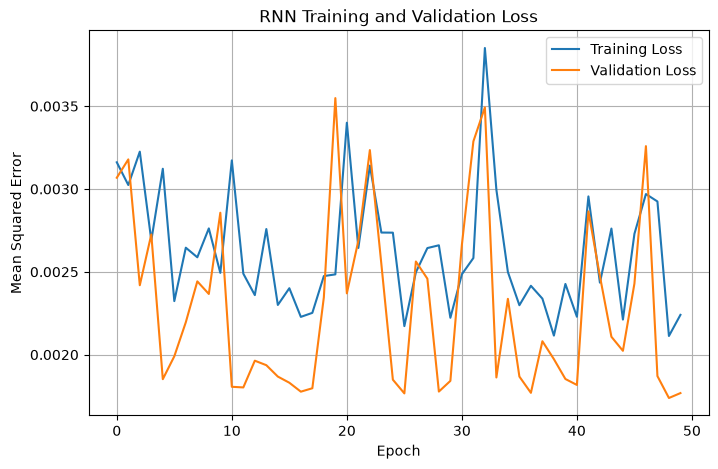

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("RNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

## 15. Make Predictions and Convert Back to Celsius

In [27]:
y_pred_scaled = model.predict(X_test)

# Inverse-transform only the target column.
target_scaler_min = scaler.data_min_[temperature_index]
target_scaler_range = scaler.data_range_[temperature_index]

y_test_actual = y_test * target_scaler_range + target_scaler_min
y_pred_actual = y_pred_scaled.reshape(-1) * target_scaler_range + target_scaler_min

results = pd.DataFrame({
    "Actual Temperature (C)": y_test_actual,
    "Predicted Temperature (C)": y_pred_actual
}, index=data.index[target_positions[test_mask]])

display(results.head(10))

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


,Actual Temperature (C),Predicted Temperature (C)
Formatted Date,,
2014-10-20 00:00:00+00:00,14.743750,11.771171
2014-10-21 00:00:00+00:00,14.340972,15.026470
2014-10-22 00:00:00+00:00,9.575000,13.942178
2014-10-23 00:00:00+00:00,8.143287,6.449126
2014-10-24 00:00:00+00:00,7.901852,9.045650
2014-10-25 00:00:00+00:00,7.822917,8.227266
2014-10-26 00:00:00+00:00,6.696296,7.378715
2014-10-27 00:00:00+00:00,3.885417,6.556476
2014-10-28 00:00:00+00:00,4.854630,3.627393


## 16. Evaluate the Model

In [28]:
mae = mean_absolute_error(y_test_actual, y_pred_actual)
mse = mean_squared_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_actual, y_pred_actual)

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 1.6037
Mean Squared Error (MSE): 4.6346
Root Mean Squared Error (RMSE): 2.1528
R2 Score: 0.9335


## 17. Plot Actual vs Predicted Temperature

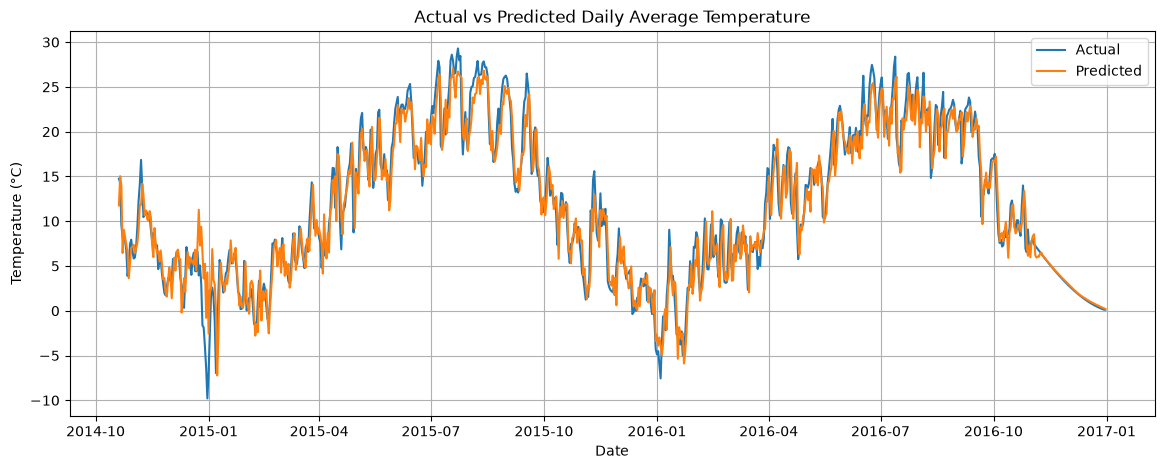

In [29]:
plt.figure(figsize=(14, 5))
plt.plot(results.index, results["Actual Temperature (C)"], label="Actual")
plt.plot(results.index, results["Predicted Temperature (C)"], label="Predicted")
plt.title("Actual vs Predicted Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

## 18. Predict the Next 7 Day's Temperature

In [30]:
# Predict the next 7 days

last_sequence = scaled_values[-TIME_STEPS:, :].copy()

future_predictions = []

for i in range(7):
    input_sequence = last_sequence.reshape(
        1, TIME_STEPS, len(feature_columns)
    )

    next_day_scaled = model.predict(
        input_sequence, verbose=0
    )[0, 0]

    next_day_temperature = (
        next_day_scaled * target_scaler_range
        + target_scaler_min
    )

    future_predictions.append(next_day_temperature)

    next_row = last_sequence[-1].copy()
    next_row[temperature_index] = next_day_scaled

    last_sequence = np.vstack([
        last_sequence[1:],
        next_row
    ])

future_dates = pd.date_range(
    start=data.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

future_df = pd.DataFrame({
    "Predicted Temperature (C)": future_predictions
}, index=future_dates)

display(future_df)

,Predicted Temperature (C)
2017-01-01 00:00:00+00:00,0.210074
2017-01-02 00:00:00+00:00,0.290317
2017-01-03 00:00:00+00:00,0.337299
2017-01-04 00:00:00+00:00,0.371694
2017-01-05 00:00:00+00:00,0.377974
2017-01-06 00:00:00+00:00,0.380408
2017-01-07 00:00:00+00:00,0.377404


 ## 19. Visualize the Next 7 Days' Temperature Forecast

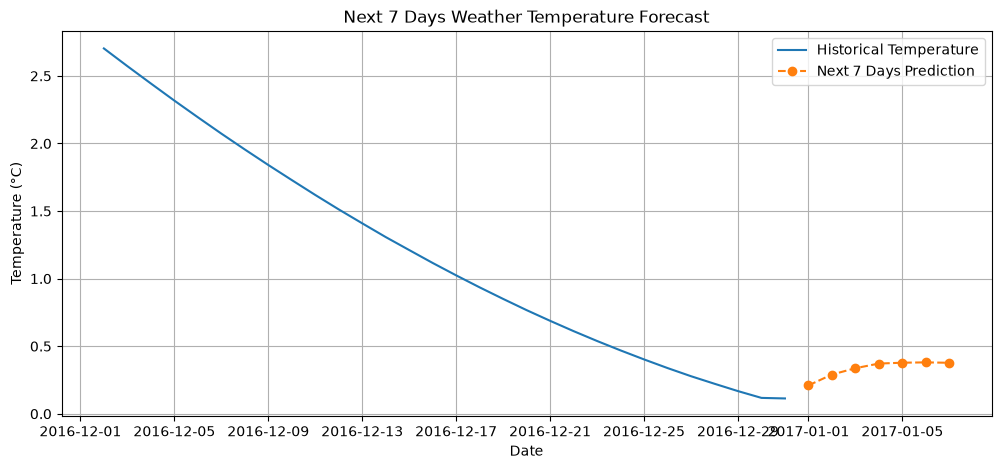

In [31]:

plt.figure(figsize=(12, 5))

# Recent historical temperature
plt.plot(
    daily_df.index[-30:],
    daily_df["Temperature (C)"].iloc[-30:],
    label="Historical Temperature"
)

# Future predicted temperature
plt.plot(
    future_df.index,
    future_df["Predicted Temperature (C)"],
    marker="o",
    linestyle="--",
    label="Next 7 Days Prediction"
)

plt.title("Next 7 Days Weather Temperature Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

## Conclusion ##



In this assignment, hourly weather observations were converted into daily weather records. A Simple RNN model was trained using the previous seven days of weather measurements to predict the next day's average temperature.

The model performance was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score. Actual and predicted temperatures were compared using visualization.

Finally, the trained model was used to predict the temperature for the next seven days. The future predictions were displayed in a table and visualized using a graph along with recent historical temperature data.

**Note:** The seven-day forecast is a learning exercise based on historical data. Since future values of other weather features are unavailable, their latest observed values are kept constant during prediction.